Premiere exploration des données de Allergie -passage aux urgances

In [1]:
#import des librairies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [2]:
#pour construire le chemin d'accès aux fichiers de données
from pathlib import Path

raw = Path(r"C:\Users\monik\Documents\3_PRO\3_LEARNING\13_Formation_DATA_SCIENTIST\Projet\Fil_rouge\GitHub\LIORA_PROJET_PATHO_RESPIRATOIRES\notebooks")

print(list(raw.iterdir()))

[WindowsPath('C:/Users/monik/Documents/3_PRO/3_LEARNING/13_Formation_DATA_SCIENTIST/Projet/Fil_rouge/GitHub/LIORA_PROJET_PATHO_RESPIRATOIRES/notebooks/01a.Exploration_asthme_MLU.ipynb'), WindowsPath('C:/Users/monik/Documents/3_PRO/3_LEARNING/13_Formation_DATA_SCIENTIST/Projet/Fil_rouge/GitHub/LIORA_PROJET_PATHO_RESPIRATOIRES/notebooks/01b.Exploration_visuelle_asthme_MLU2.ipynb'), WindowsPath('C:/Users/monik/Documents/3_PRO/3_LEARNING/13_Formation_DATA_SCIENTIST/Projet/Fil_rouge/GitHub/LIORA_PROJET_PATHO_RESPIRATOIRES/notebooks/02a.Exploration_allergie_MLU .ipynb'), WindowsPath('C:/Users/monik/Documents/3_PRO/3_LEARNING/13_Formation_DATA_SCIENTIST/Projet/Fil_rouge/GitHub/LIORA_PROJET_PATHO_RESPIRATOIRES/notebooks/02b.Exploration_visuelle_allergie_MLU.ipynb'), WindowsPath('C:/Users/monik/Documents/3_PRO/3_LEARNING/13_Formation_DATA_SCIENTIST/Projet/Fil_rouge/GitHub/LIORA_PROJET_PATHO_RESPIRATOIRES/notebooks/03a.Exploration_bronchiolite_MLU.ipynb'), WindowsPath('C:/Users/monik/Documents/3

In [3]:
#pour construire le chemin d'accès aux fichiers de données

from pathlib import Path

raw = Path("../data/raw")

# Afficher tous les fichiers CSV, y compris dans les sous-dossiers
for fichier in raw.rglob("*.csv"):
    print(fichier)

..\data\raw\allergie-passages-aux-urgences-et-actes-sos-medecins-dep.csv
..\data\raw\asthme-passages-aux-urgences-et-actes-sos-medecins-dep.csv
..\data\raw\bronchiolite-passages-aux-urgences-et-actes-sos-medecins-departement.csv
..\data\raw\pollut_20261012084158 - 2025-01-01 00_00 - 2025-12-31 23_00.csv
..\data\raw\pollut_20261012084855 - 2025-01-01 00_00 - 2025-12-31 23_00.csv
..\data\raw\pollut_20261012084932 - 2025-01-01 00_00 - 2025-12-31 23_00.csv
..\data\raw\pollut_20261012085004 - 2025-01-01 00_00 - 2025-12-31 23_00.csv
..\data\raw\pollut_20261012085038 - 2025-01-01 00_00 - 2025-12-31 23_00.csv
..\data\raw\Sante\allergie-passages-aux-urgences-et-actes-sos-medecins-dep.csv
..\data\raw\Sante\asthme-passages-aux-urgences-et-actes-sos-medecins-dep.csv
..\data\raw\Sante\bronchiolite-passages-aux-urgences-et-actes-sos-medecins-departement.csv
..\data\raw\Sante\effectifs.csv


In [4]:
df_allergie = pd.read_csv(
    "../data/raw/Sante/allergie-passages-aux-urgences-et-actes-sos-medecins-dep.csv"
)
df_allergie.head()

,1er jour de la semaine,Semaine,Département Code,Département,Classe d'âge,Taux de passages aux urgences pour allergie,Taux d'hospitalisations après passages aux urgences pour allergie,Taux d'actes médicaux SOS médecins pour allergie,Région Code,Région
0,2026-09-28,2026-S40,23,Creuse,Tous âges,2553.191489,4000.0,NaN,75,Nouvelle Aquitaine
1,2026-09-28,2026-S40,25,Doubs,Tous âges,489.236791,800.0,760.043431,27,Bourgogne et Franche-Comté
2,2026-09-28,2026-S40,26,Drôme,65 ans ou plus,300.300300,0.0,NaN,84,Auvergne et Rhône-Alpes
3,2026-09-28,2026-S40,27,Eure,65 ans ou plus,381.194409,0.0,NaN,28,Normandie
4,2026-09-28,2026-S40,31,Haute-Garonne,00-14 ans,608.930988,0.0,1041.666667,76,Occitanie


In [5]:
#info generale sur le dataframe
df_allergie.info()

<class 'pandas.DataFrame'>
RangeIndex: 121200 entries, 0 to 121199
Data columns (total 10 columns):
 #   Column                                                             Non-Null Count   Dtype  
---  ------                                                             --------------   -----  
 0   1er jour de la semaine                                             121200 non-null  str    
 1   Semaine                                                            121200 non-null  str    
 2   Département Code                                                   121200 non-null  str    
 3   Département                                                        121200 non-null  str    
 4   Classe d'âge                                                       121200 non-null  str    
 5   Taux de passages aux urgences pour allergie                        120700 non-null  float64
 6   Taux d'hospitalisations après passages aux urgences pour allergie  120116 non-null  float64
 7   Taux d'actes médicaux 

In [6]:
#combien de colonne et de lignes
df_allergie.shape

(121200, 10)

Verification la presence des doublons

In [7]:
df_allergie.duplicated()

print(df_allergie.duplicated().sum())

0


Verification des valeurs manquantes

In [8]:
#mesurer les valeurs manquantes : afficher le nombre de valeurs manquantes par colonne
df_allergie.isna().sum()


1er jour de la semaine                                                   0
Semaine                                                                  0
Département Code                                                         0
Département                                                              0
Classe d'âge                                                             0
Taux de passages aux urgences pour allergie                            500
Taux d'hospitalisations après passages aux urgences pour allergie     1084
Taux d'actes médicaux SOS médecins pour allergie                     66522
Région Code                                                              0
Région                                                                   0
dtype: int64

In [9]:
# pourcentage de valeurs manquantes par colonne
df_allergie.isna().mean().mul(100)

1er jour de la semaine                                                0.000000
Semaine                                                               0.000000
Département Code                                                      0.000000
Département                                                           0.000000
Classe d'âge                                                          0.000000
Taux de passages aux urgences pour allergie                           0.412541
Taux d'hospitalisations après passages aux urgences pour allergie     0.894389
Taux d'actes médicaux SOS médecins pour allergie                     54.886139
Région Code                                                           0.000000
Région                                                                0.000000
dtype: float64

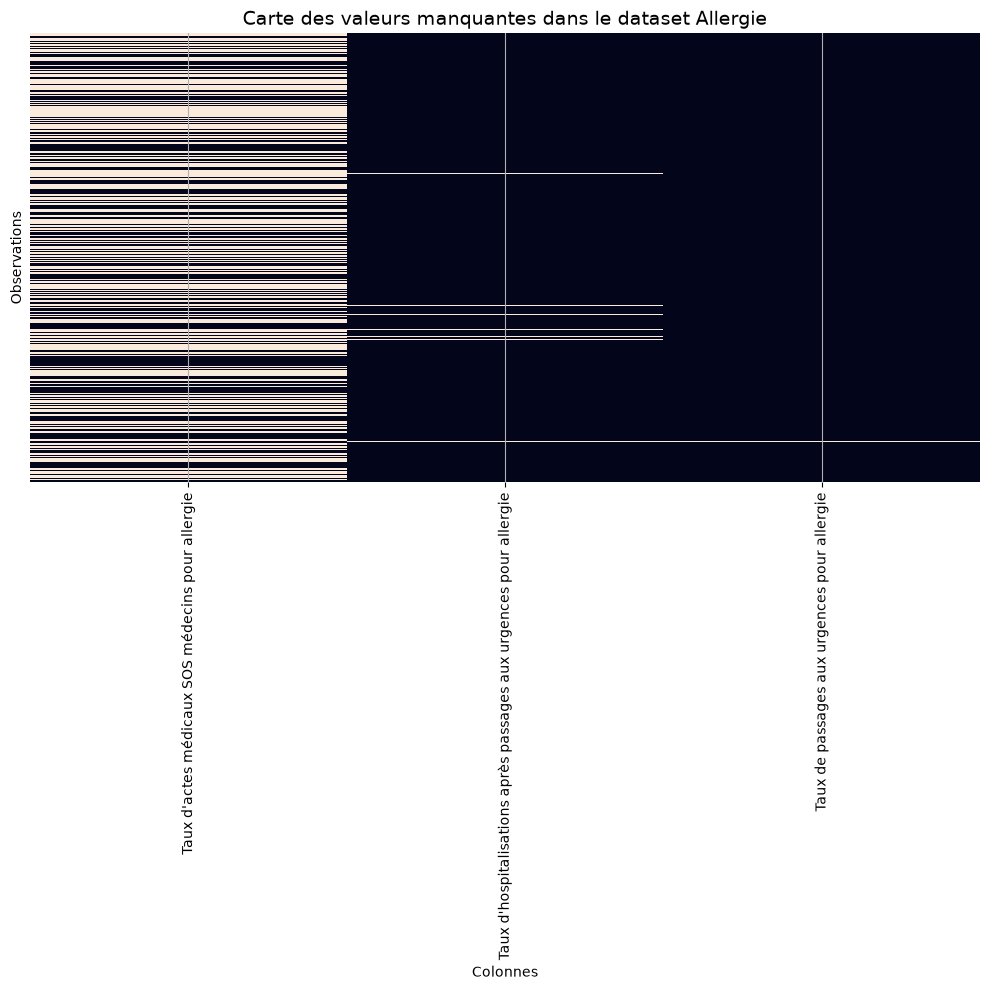

In [23]:
# Affiche le nombre de valeurs manquantes par colonne
missing_values = df_allergie.isna().sum()[lambda x: x > 0].sort_values(ascending=False)      #[lambda x: x > 0] → garde uniquement les colonnes qui ont au moins une valeur manquante.


# Visualisation: Heatmap des valeurs manquantes
plt.figure(figsize=(10, 10))
sns.heatmap(df_allergie[missing_values.index].isna(), cbar=False, yticklabels=False)
plt.title("Carte des valeurs manquantes dans le dataset Allergie", fontsize=14)
plt.xlabel("Colonnes")
plt.ylabel("Observations")
plt.tight_layout()
plt.grid(True)
plt.show()


In [ ]:
#afficher les colonnes entierement vides pour les 3 taux cibles
colonnes = ["Taux de passages aux urgences pour allergie", "Taux d'hospitalisations après passages aux urgences pour allergie", "Taux d'actes médicaux SOS médecins pour allergie"]

display(df_allergie[df_allergie[colonnes].isna().all(axis=1)])

,1er jour de la semaine,Semaine,Département Code,Département,Classe d'âge,Taux de passages aux urgences pour allergie,Taux d'hospitalisations après passages aux urgences pour allergie,Taux d'actes médicaux SOS médecins pour allergie,Région Code,Région
97010,2022-02-21,2022-S08,972,Martinique,00-14 ans,NaN,NaN,NaN,2,Martinique
97225,2022-02-21,2022-S08,972,Martinique,15-64 ans,NaN,NaN,NaN,2,Martinique
97226,2022-02-21,2022-S08,972,Martinique,65 ans ou plus,NaN,NaN,NaN,2,Martinique
97247,2022-02-21,2022-S08,972,Martinique,Tous âges,NaN,NaN,NaN,2,Martinique


In [11]:
#Valeurs uniques par colonnes
colonnes = df_allergie.columns.tolist()
df_allergie[colonnes].nunique()

1er jour de la semaine                                                 300
Semaine                                                                300
Département Code                                                       101
Département                                                            101
Classe d'âge                                                             4
Taux de passages aux urgences pour allergie                          35004
Taux d'hospitalisations après passages aux urgences pour allergie     6611
Taux d'actes médicaux SOS médecins pour allergie                     18746
Région Code                                                             18
Région                                                                  18
dtype: int64

In [12]:
#quelles sont les valeurs uniques dans la colonne "Classe d'âge"
df_allergie["Classe d'âge"].unique()

<StringArray>
['Tous âges', '65 ans ou plus', '00-14 ans', '15-64 ans']
Length: 4, dtype: str

In [13]:
#Statistiques descriptives pour la colonne "Taux de passages aux urgences pour allergie"
df_allergie["Taux de passages aux urgences pour allergie"].describe()

count    120700.000000
mean        725.997985
std         513.682658
min           0.000000
25%         395.778364
50%         655.737705
75%         950.232568
max        8000.000000
Name: Taux de passages aux urgences pour allergie, dtype: float64

In [14]:
#Statistiques descriptives pour la colonne "Taux d'hospitalisations après passages aux urgences pour allergie"
df_allergie["Taux d'hospitalisations après passages aux urgences pour allergie"].describe()

count    120116.000000
mean        369.793756
std         978.976526
min           0.000000
25%           0.000000
50%           0.000000
75%         450.450450
max      100000.000000
Name: Taux d'hospitalisations après passages aux urgences pour allergie, dtype: float64

In [15]:
#Statistiques descriptives pour la colonne "Taux d'actes médicaux SOS médecins pour allergie" 
df_allergie["Taux d'actes médicaux SOS médecins pour allergie"].describe()

count    54678.000000
mean      1669.814035
std       1335.952166
min          0.000000
25%        806.451613
50%       1388.888889
75%       2212.389380
max      50000.000000
Name: Taux d'actes médicaux SOS médecins pour allergie, dtype: float64

In [16]:
#Valeurs manquantes par département pour la colonne "Taux d'actes médicaux SOS médecins pour allergie"
manquant1 = df_allergie["Taux d'actes médicaux SOS médecins pour allergie"].isna()

taux_manquants = (
    manquant1.groupby(df_allergie["Département Code"])
    .mean()*100
)

taux_manquants.sort_values(ascending=False)

Département Code
01    100.0
03    100.0
04    100.0
05    100.0
07    100.0
      ...  
80      0.0
73      0.0
91      0.0
87      0.0
89      0.0
Name: Taux d'actes médicaux SOS médecins pour allergie, Length: 101, dtype: float64

In [17]:
#Valeurs manquantes par département pour la colonne "Taux d'hospitalisations après passages aux urgences pour asthme"
manquant2 = df_allergie["Taux d'hospitalisations après passages aux urgences pour allergie"].isna()

taux_manquants = (
    manquant2.groupby(df_allergie["Département Code"])
    .mean()*100
)

taux_manquants.sort_values(ascending=False)

Département Code
972    41.666667
55     34.333333
48      5.500000
23      4.500000
43      1.083333
         ...    
94      0.000000
971     0.000000
95      0.000000
973     0.000000
974     0.000000
Name: Taux d'hospitalisations après passages aux urgences pour allergie, Length: 101, dtype: float64

In [18]:
#Valeurs manquantes par département pour la colonne "Taux de passages aux urgences pour allergie"
manquant3 = df_allergie["Taux de passages aux urgences pour allergie"].isna()

taux_manquants = (
    manquant3.groupby(df_allergie["Département Code"])
    .mean()*100
)

taux_manquants.sort_values(ascending=False)

Département Code
972    41.666667
02      0.000000
03      0.000000
04      0.000000
01      0.000000
         ...    
94      0.000000
971     0.000000
973     0.000000
974     0.000000
976     0.000000
Name: Taux de passages aux urgences pour allergie, Length: 101, dtype: float64

Verification la coherence  des colonnes redondantes

In [19]:
#comparer si "Semaine" correspond à "1er jour de la semaine" pour chaque ligne :
#0 je fais un copie pour pas modifier l'originale df_allergie
df_allergie2 = df_allergie.copy()
# 1. Tranformation de la date en numero de semaine
# nettoyage
df_allergie2.columns = (
    df_allergie2.columns
    .str.replace(" ", "_")
    .str.strip()
)

df_allergie2.info()

#2. Transformation de la colonne "1er_jour_de_la_semaine" en datetime (date impossible devient NaT, valeur manquant)
col_date = "1er_jour_de_la_semaine"

dates = pd.to_datetime(
    df_allergie2[col_date], format="%Y-%m-%d", errors="coerce"
)

#extraire l'année et la semaine de la date
iso = dates.dt.isocalendar()

#reconstruction de la meme format que la colonne "Semaine" : "YYYY-SWW"
semaine_calculee = (
    iso["year"].astype("string")
    + "-S"
    + iso["week"].astype("string").str.zfill(2)
)


semaine_source = df_allergie["Semaine"]

#Verification
valide = (
    semaine_source.notna()                      #La semaine est renseignée
    & dates.notna()                             #La date est present et pu etre convertie  
    & semaine_source.eq(semaine_calculee)       #La semaine correspond à la date
    & dates.dt.dayofweek.eq(0)                  #La date est un lundi (0 = lundi, 1 = mardi, ..., 6 = dimanche)
).fillna(False)

print(f"{valide.sum()} lignes cohérentes sur {len(df_allergie2)}")




<class 'pandas.DataFrame'>
RangeIndex: 121200 entries, 0 to 121199
Data columns (total 10 columns):
 #   Column                                                             Non-Null Count   Dtype  
---  ------                                                             --------------   -----  
 0   1er_jour_de_la_semaine                                             121200 non-null  str    
 1   Semaine                                                            121200 non-null  str    
 2   Département_Code                                                   121200 non-null  str    
 3   Département                                                        121200 non-null  str    
 4   Classe_d'âge                                                       121200 non-null  str    
 5   Taux_de_passages_aux_urgences_pour_allergie                        120700 non-null  float64
 6   Taux_d'hospitalisations_après_passages_aux_urgences_pour_allergie  120116 non-null  float64
 7   Taux_d'actes_médicaux_

In [20]:

#comparer si Region correspond à Région Code pour chaque ligne 
    #Est-ce que chaque nom de région possède un seul code ?
    #Est-ce que chaque code possède un seul nom de région ?

#creation tableau de travail
paires = df_allergie2[["Région", "Région_Code"]].copy()

#pour chaque colonne on transforme en texte, retire les espaces et remplace les valeurs vides par NaN si applicable
for col in ["Région", "Région_Code"]:
    paires[col] = (
        paires[col].astype("string").str.strip().replace("", pd.NA)
    )


#Garder les associations distinctes et complètes et on retire les repetitions des lignes entieres pour ne garder que les paires uniques
# Garder une seule fois chaque association région / code
paires = df_allergie2[
    ["Région", "Région_Code"]
].drop_duplicates()

# Chercher les noms associés à plusieurs codes
# ou les codes associés à plusieurs noms
conflits = paires[
    paires.duplicated("Région", keep=False)
    | paires.duplicated("Région_Code", keep=False)
]

display(conflits)



,Région,Région_Code


In [21]:
#comparer si Département correspond à Département Code pour chaque ligne

    #Est-ce que chaque nom de département possède un seul code ?
    #Est-ce que chaque code possède un seul nom de departement ?

#creation tableau de travail
paires = df_allergie2[["Département", "Département_Code"]].copy()

#pour chaque colonne on transforme en texte, retire les espaces et remplace les valeurs vides par NaN si applicable
for col in ["Département", "Département_Code"]:
    paires[col] = (
        paires[col].astype("string").str.strip().replace("", pd.NA)
    )


#Garder les associations distinctes et complètes et on retire les repetitions des lignes entieres pour ne garder que les paires uniques
# Garder une seule fois chaque association département / code
paires = df_allergie2[
    ["Département", "Département_Code"]
].drop_duplicates()

# Chercher les noms associés à plusieurs codes
# ou les codes associés à plusieurs noms
conflits = paires[
    paires.duplicated("Département", keep=False)
    | paires.duplicated("Département_Code", keep=False)
]

display(conflits)


,Département,Département_Code


Lignes avec une information manquante : 0
Paires impliquées dans une correspondance ambiguë : 0

Attention! Cela ne garantit pas que les codes sont officiellement corrects. Une mauvaise association répétée partout passerait ce contrôle. La vérification officielle nécessite un référentiel adapté à la période des données.

In [22]:
#Renommer les colonnes

df_allergie2 = df_allergie2.rename(columns={
    "Taux_de_passages_aux_urgences_pour_allergie": "taux_urgences",
    "Taux_d'hospitalisations_après_passages_aux_urgences_pour_allergie": "taux_hospitalisations",
    "Taux_d'actes_médicaux_SOS_médecins_pour_allergie": "taux_sos"
})

df_allergie2.head()

,1er_jour_de_la_semaine,Semaine,Département_Code,Département,Classe_d'âge,taux_urgences,taux_hospitalisations,taux_sos,Région_Code,Région
0,2026-09-28,2026-S40,23,Creuse,Tous âges,2553.191489,4000.0,NaN,75,Nouvelle Aquitaine
1,2026-09-28,2026-S40,25,Doubs,Tous âges,489.236791,800.0,760.043431,27,Bourgogne et Franche-Comté
2,2026-09-28,2026-S40,26,Drôme,65 ans ou plus,300.300300,0.0,NaN,84,Auvergne et Rhône-Alpes
3,2026-09-28,2026-S40,27,Eure,65 ans ou plus,381.194409,0.0,NaN,28,Normandie
4,2026-09-28,2026-S40,31,Haute-Garonne,00-14 ans,608.930988,0.0,1041.666667,76,Occitanie
